In [29]:
!pip install pydeseq2 gseapy

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
print(pd.__version__)


3.1.1


In [31]:
from pydeseq2.utils import load_example_data

counts = load_example_data(modality="raw_counts", dataset="synthetic", debug=False)
metadata = load_example_data(modality="metadata", dataset="synthetic", debug=False)

print(counts.shape)
print(counts.head())
print(metadata)

(100, 10)
         gene1  gene2  gene3  gene4  gene5  gene6  gene7  gene8  gene9  gene10
sample1     12     21      4    130     18      0     16     54     49       3
sample2      1     44      2     63     11     10     70     32     57       9
sample3      4      4     11    180     21      3     28     34     65       2
sample4      1     10      2    100     44      9     28     16     33       9
sample5      1     11      6    135     16      2     32     29     31       5
          condition group
sample1           A     X
sample2           A     Y
sample3           A     X
sample4           A     Y
sample5           A     X
...             ...   ...
sample96          B     Y
sample97          B     X
sample98          B     Y
sample99          B     X
sample100         B     Y

[100 rows x 2 columns]


In [32]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

dds = DeseqDataSet(counts=counts, metadata=metadata, design="~condition")
dds.deseq2()

stat_res = DeseqStats(dds, contrast=("condition", "B", "A"))
stat_res.summary()
results = stat_res.results_df
print(results.head())

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.12 seconds.

Fitting dispersion trend curve...
... done in 0.07 seconds.

Fitting MAP dispersions...
... done in 0.11 seconds.

Fitting LFCs...
... done in 0.06 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.04 seconds.



Log2 fold change & Wald test p-value: condition B vs A
          baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
gene1     8.541317        0.632812  0.289101  2.188898  0.028604  0.064150
gene2    21.281239        0.538552  0.149963  3.591236  0.000329  0.001646
gene3     5.010123       -0.632830  0.295236 -2.143476  0.032075  0.064150
gene4   100.517961       -0.412102  0.118629 -3.473868  0.000513  0.001710
gene5    27.142450        0.582065  0.154706  3.762409  0.000168  0.001646
gene6     5.413043        0.001457  0.310311  0.004696  0.996253  0.996253
gene7    28.294023        0.134338  0.149945  0.895917  0.370297  0.411441
gene8    40.358344       -0.270656  0.136401 -1.984261  0.047227  0.078711
gene9    37.166183       -0.212715  0.133243 -1.596437  0.110391  0.143147
gene10   11.589325        0.386011  0.244588  1.578207  0.114518  0.143147
         baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
gene1    8.541317        0.632812  0.289101  2

In [33]:
counts = pd.read_csv("counts.tsv.gz", sep="\t", index_col=0)
print(counts.shape)
counts.head()


(39376, 16)


,GSM1275862,GSM1275863,GSM1275864,GSM1275865,GSM1275866,GSM1275867,GSM1275868,GSM1275869,GSM1275870,GSM1275871,GSM1275872,GSM1275873,GSM1275874,GSM1275875,GSM1275876,GSM1275877
GeneID,,,,,,,,,,,,,,,,
100287102,6,8,8,3,5,10,11,7,6,8,4,10,2,1,2,2
653635,357,292,351,285,469,428,523,442,367,415,404,354,371,381,367,341
102466751,12,11,12,10,15,15,19,15,9,11,18,9,10,9,12,6
107985730,1,1,2,1,3,2,2,3,1,1,1,1,2,1,1,1
100302278,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,1


In [34]:
meta = pd.DataFrame({
    "cell": ["N61311","N61311","N052611","N052611","N080611","N080611","N061011","N061011"],
    "dex":  ["control","dex"]*4,
}, index=["GSM1275862","GSM1275863","GSM1275866","GSM1275867",
          "GSM1275870","GSM1275871","GSM1275874","GSM1275875"])

counts = counts[meta.index]
print(counts.shape)
meta

(39376, 8)


,cell,dex
GSM1275862,N61311,control
GSM1275863,N61311,dex
GSM1275866,N052611,control
GSM1275867,N052611,dex
GSM1275870,N080611,control
GSM1275871,N080611,dex
GSM1275874,N061011,control
GSM1275875,N061011,dex


In [35]:
annot = pd.read_csv("annot.tsv.gz", sep="\t", index_col=0)
print(annot.columns.tolist())

['Symbol', 'Description', 'Synonyms', 'GeneType', 'EnsemblGeneID', 'Status', 'ChrAcc', 'ChrStart', 'ChrStop', 'Orientation', 'Length', 'GOFunctionID', 'GOProcessID', 'GOComponentID', 'GOFunction', 'GOProcess', 'GOComponent']


/tmp/ipykernel_2212/3440377195.py:1: DtypeWarning: Columns (8: ChrStart, 9: ChrStop) have mixed types. Specify dtype option on import or set low_memory=False.
  annot = pd.read_csv("annot.tsv.gz", sep="\t", index_col=0)


In [36]:
counts["Symbol"] = counts.index.map(annot["Symbol"])
counts = counts.dropna(subset=["Symbol"])
counts = counts.groupby("Symbol").sum()
print(counts.shape)

(39374, 8)


In [37]:
counts = counts.T.astype(int)
print(counts.shape)

counts = counts.loc[:, counts.sum(axis=0) >= 10]
print(counts.shape)

(8, 39374)
(8, 21833)


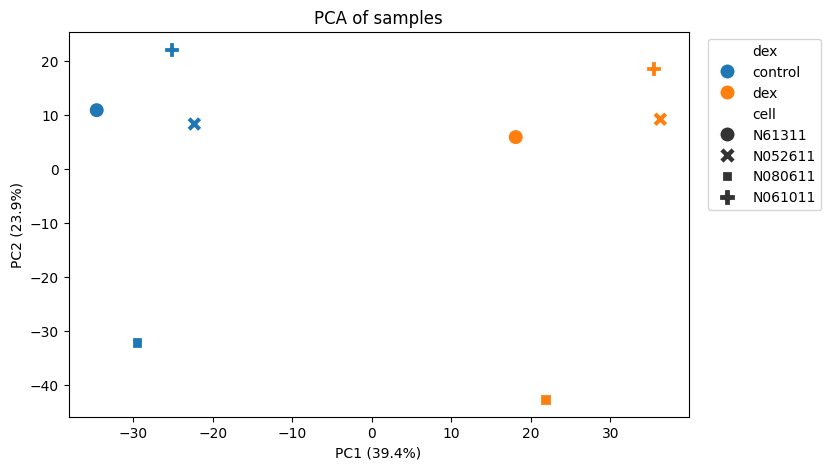

In [52]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(logcpm)
pca_df = pd.DataFrame(pcs, index=logcpm.index, columns=["PC1","PC2"])
pca_df["dex"] = meta["dex"]
pca_df["cell"] = meta["cell"]

plt.figure(figsize=(8,5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="dex", style="cell", s=120)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of samples")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.savefig("pca.png", dpi=300, bbox_inches="tight")
plt.show()

In [53]:
from google.colab import files
files.download("pca.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
paper_top = ["C7","CCDC69","DUSP1","FKBP5","GPX3","KLF15","MAOA","SAMHD1",
             "SERPINA3","SPARCL1","C13orf15","RGCC","TSC22D3","CRISPLD2",
             "PER1","KCTD12","ERRFI1","STEAP4"]

found = results.loc[results.index.isin(paper_top), ["log2FoldChange","padj"]].sort_values("padj")
print(found)
print()
print("Of these, significant in your analysis:", found.index.isin(sig.index).sum())
print("Not in your table:", [g for g in paper_top if g not in results.index])
print("Your genes with padj < 0.05 only (no fold-change cutoff):", (results["padj"] < 0.05).sum())

          log2FoldChange           padj
Symbol                                 
SPARCL1         4.622973  1.472014e-167
SAMHD1          3.779021  1.669298e-151
MAOA            3.347768  8.084828e-147
GPX3            3.741471  1.227842e-141
DUSP1           2.960936  3.652705e-138
SERPINA3        3.232620  4.038775e-134
KLF15           4.417329  4.813368e-114
PER1            3.227582   6.793644e-99
CCDC69          2.945814   1.310481e-94
KCTD12         -2.527019   1.393390e-88
ERRFI1          2.413560   1.598839e-69
CRISPLD2        2.633986   8.547156e-61
STEAP4          5.094559   1.276563e-26
FKBP5           4.036735   2.261764e-26
TSC22D3         3.212563   1.934716e-19
C7              3.206558   2.297972e-13
RGCC            2.882512   7.711385e-05

Of these, significant in your analysis: 17
Not in your table: ['C13orf15']
Your genes with padj < 0.05 only (no fold-change cutoff): 4548


In [39]:
enr_up.results[["Term","Adjusted P-value"]].head(3)

,Term,Adjusted P-value
0,Negative Regulation Of Cell Motility (GO:2000146),0.004686
1,Regulation Of Cell Migration (GO:0030334),0.007013
2,Negative Regulation Of Cell Migration (GO:0030...,0.021434


In [40]:
enr_up.results[["Term","Genes"]].head(3).to_string()

'                                                 Term                                                                                                                                                                                 Genes\n0   Negative Regulation Of Cell Motility (GO:2000146)                                                                                          EPHA4;KANK1;MCTP1;CITED2;NOG;STC1;NEDD9;ADARB1;SPINT2;FOXO3;ALOX15B;SAP30;RHOB;ING2;NAV3;NF2\n1           Regulation Of Cell Migration (GO:0030334)  KANK1;MCTP1;CITED2;FAM107A;STC1;NEDD9;NEXN;PRR5L;ADARB1;FGF1;FOXO3;THBS1;NKD1;ING2;PDPN;PTK2B;PLXNA4;FGF22;EPHA4;CARMIL1;SUN2;MMP7;NOG;ALOX15B;SAP30;RHOB;CCNA2;NAV3;DAAM2;MYADM;NF2\n2  Negative Regulation Of Cell Migration (GO:0030336)                                                                                         EPHA4;KANK1;MCTP1;CITED2;NOG;STC1;NEDD9;ADARB1;FOXO3;ALOX15B;SAP30;RHOB;ING2;NAV3;ARHGDIB;NF2'

In [41]:
down_genes = sig[sig["log2FoldChange"] < 0].index.tolist()
enr_down = gp.enrichr(gene_list=down_genes, gene_sets=["GO_Biological_Process_2023"],
                      organism="human", outdir=None)
enr_down.results[["Term","Adjusted P-value"]].head(3)

,Term,Adjusted P-value
0,Axonogenesis (GO:0007409),0.001426
1,Axon Guidance (GO:0007411),0.001872
2,Neuron Projection Guidance (GO:0097485),0.011571


In [42]:
dds = DeseqDataSet(counts=counts, metadata=meta, design="~cell + dex")
dds.deseq2()

stat_res = DeseqStats(dds, contrast=("dex", "dex", "control"))
stat_res.summary()
results = stat_res.results_df.dropna(subset=["padj"]).copy()

Fitting size factors...
... done in 0.03 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 35.41 seconds.

Fitting dispersion trend curve...
... done in 1.44 seconds.

/usr/local/lib/python3.13/dist-packages/pydeseq2/dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 30.06 seconds.

Fitting LFCs...
... done in 20.78 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 8.70 seconds.



Log2 fold change & Wald test p-value: dex dex vs control
              baseMean  log2FoldChange     lfcSE      stat        pvalue  \
Symbol                                                                     
A1BG        196.602580        0.318268  0.157737  2.017708  4.362169e-02   
A1BG-AS1    116.140104        0.535060  0.193015  2.772119  5.569273e-03   
A2M       30103.390796        0.554080  0.427082  1.297362  1.945068e-01   
A2M-AS1     329.992453        0.465123  0.183423  2.535790  1.121941e-02   
A2ML1         1.754353       -1.167178  1.573181 -0.741922  4.581343e-01   
...                ...             ...       ...       ...           ...   
ZYG11A       21.110205       -0.366716  0.416494 -0.880482  3.785983e-01   
ZYG11B     1579.322493        0.022328  0.102503  0.217831  8.275605e-01   
ZYX       10968.799124        0.709474  0.096975  7.316058  2.553606e-13   
ZZEF1      2404.455316        0.076979  0.100027  0.769587  4.415449e-01   
ZZZ3       1084.811288       -0

In [43]:
results.loc[results.index.isin(["CRISPLD2","DUSP1","KLF15"])]

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Symbol,,,,,,
CRISPLD2,4022.260568,2.633986,0.156619,16.817812,1.807108e-63,8.547156e-61
DUSP1,4473.022174,2.960936,0.116820,25.346182,9.901076e-142,3.652705e-138
KLF15,740.763123,4.417329,0.191810,23.029730,2.348493e-117,4.813368e-114


In [44]:
sig = results[(results["padj"] < 0.05) & (results["log2FoldChange"].abs() > 1)]
print("Significant genes:", len(sig))
print("Up in dex:", (sig["log2FoldChange"] > 0).sum())
print("Down in dex:", (sig["log2FoldChange"] < 0).sum())
results.to_csv("differential_expression_results.csv")

Significant genes: 1171
Up in dex: 590
Down in dex: 581


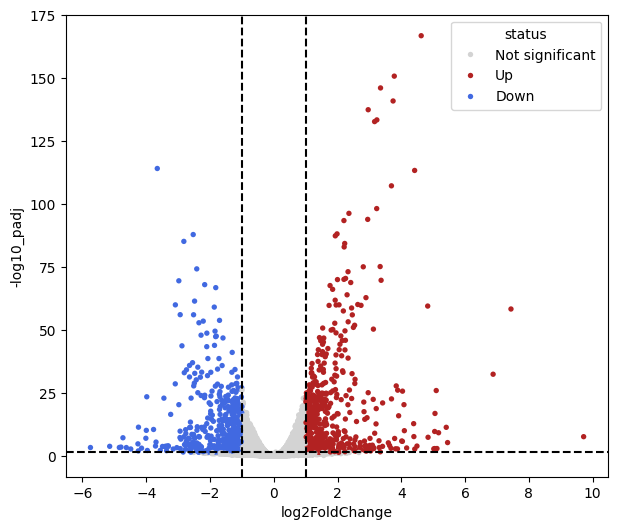

In [45]:
results["-log10_padj"] = -np.log10(results["padj"])
results["status"] = "Not significant"
results.loc[(results["padj"] < 0.05) & (results["log2FoldChange"] > 1), "status"] = "Up"
results.loc[(results["padj"] < 0.05) & (results["log2FoldChange"] < -1), "status"] = "Down"

plt.figure(figsize=(7,6))
sns.scatterplot(data=results, x="log2FoldChange", y="-log10_padj", hue="status",
                palette={"Not significant":"lightgrey","Up":"firebrick","Down":"royalblue"},
                s=15, linewidth=0)
plt.axvline(1, ls="--", c="black"); plt.axvline(-1, ls="--", c="black")
plt.axhline(-np.log10(0.05), ls="--", c="black")
plt.savefig("volcano.png", dpi=300, bbox_inches="tight")
plt.show()

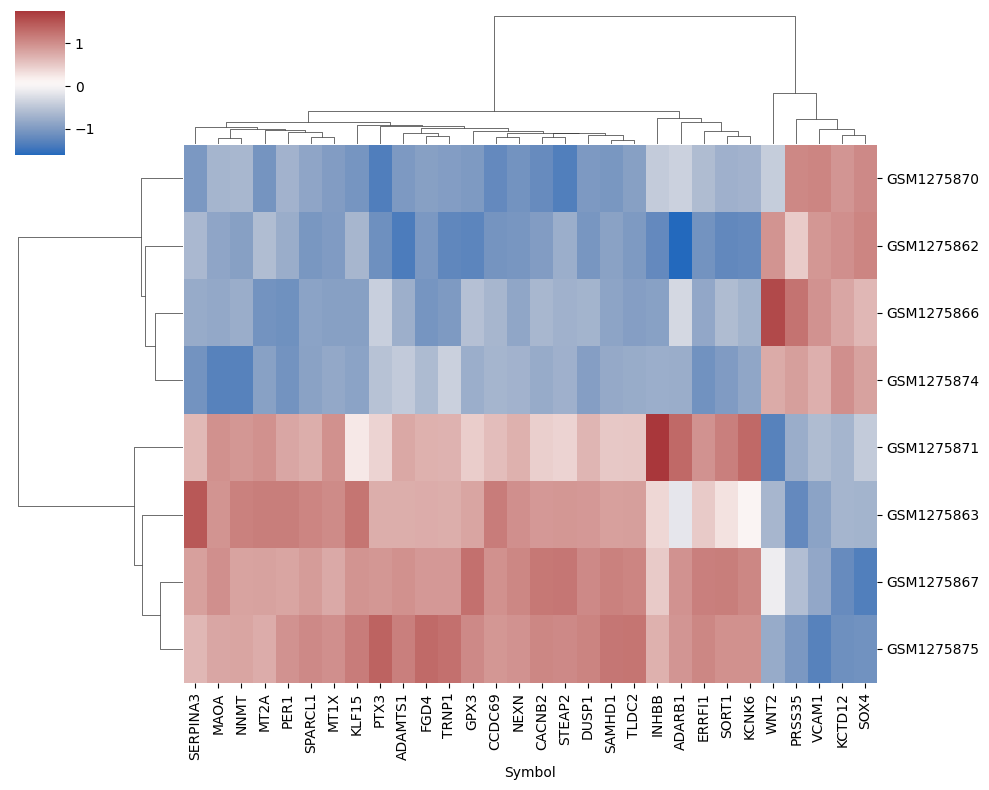

In [46]:
top_genes = results.sort_values("padj").head(30).index
g = sns.clustermap(logcpm[top_genes], z_score=1, cmap="vlag", figsize=(10,8))
g.savefig("top30_heatmap.png", dpi=300, bbox_inches="tight")

In [47]:
import gseapy as gp

up_genes = sig[sig["log2FoldChange"] > 0].index.tolist()
enr_up = gp.enrichr(gene_list=up_genes, gene_sets=["GO_Biological_Process_2023"],
                    organism="human", outdir=None)
enr_up.results[["Term","Adjusted P-value","Genes"]].head(10)

,Term,Adjusted P-value,Genes
0,Negative Regulation Of Cell Motility (GO:2000146),0.004686,EPHA4;KANK1;MCTP1;CITED2;NOG;STC1;NEDD9;ADARB1...
1,Regulation Of Cell Migration (GO:0030334),0.007013,KANK1;MCTP1;CITED2;FAM107A;STC1;NEDD9;NEXN;PRR...
2,Negative Regulation Of Cell Migration (GO:0030...,0.021434,EPHA4;KANK1;MCTP1;CITED2;NOG;STC1;NEDD9;ADARB1...
3,Positive Regulation Of Cell Differentiation (G...,0.022316,FBN2;SMARCD2;ZHX3;PKDCC;LAMA2;MMD;LMO3;ZBTB16;...
4,Response To Insulin (GO:0032868),0.044941,SORT1;LEP;ENPP1;IRS2;PPARG;INHBB;PIK3R1;SORBS1...
5,Regulation Of Substrate Adhesion-Dependent Cel...,0.044941,KANK1;CARMIL1;PDPN;MYADM;PKP2;RAC3;NEDD9;LIMS2
6,Cellular Response To Peptide Hormone Stimulus ...,0.098207,NR4A1;LHCGR;NR4A3;ENPP1;IRS2;PPARG;INHBB;PIK3R...
7,Extracellular Structure Organization (GO:0043062),0.107529,COL28A1;ADAMTS5;MMP7;COL4A1;ADAMTS1;MMP15;COL1...
8,External Encapsulating Structure Organization ...,0.107529,COL28A1;ADAMTS5;MMP7;COL4A1;ADAMTS1;MMP15;COL1...
9,Regulation Of Glucose Import (GO:0046324),0.121177,LEP;PRKAG2;ENPP1;IRS2;PIK3R1;SORBS1


In [48]:
print("Genes tested:", results.shape[0])
print("Significant genes:", len(sig))
print("Up in dex:", (sig["log2FoldChange"] > 0).sum())
print("Down in dex:", (sig["log2FoldChange"] < 0).sum())
print()
print(results.loc[results.index.isin(["CRISPLD2"]), ["baseMean","log2FoldChange","padj"]])

Genes tested: 18446
Significant genes: 1171
Up in dex: 590
Down in dex: 581

             baseMean  log2FoldChange          padj
Symbol                                             
CRISPLD2  4022.260568        2.633986  8.547156e-61


In [49]:
enr_up.results[["Term","Adjusted P-value"]].head(3)

,Term,Adjusted P-value
0,Negative Regulation Of Cell Motility (GO:2000146),0.004686
1,Regulation Of Cell Migration (GO:0030334),0.007013
2,Negative Regulation Of Cell Migration (GO:0030...,0.021434
